# Part 4: Learning from Time

Covers Project: Predicting Bulldozer Prices through Project: Forecasting Avocado Prices. The [README](README.md) has the same content with the full table of contents; datasets and versions are listed in its Setup section.

In [1]:
# Shared setup: imports and paths used throughout. Run this cell first.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # keep TensorFlow's start-up logs quiet
from pathlib import Path
import logging, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="(Degrees of freedom|divide by zero|invalid value)")  # sparse correlations
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # Prophet's backend is chatty
logging.getLogger("tensorflow").setLevel(logging.ERROR)
DATA = Path("data")
IMAGES = Path("images")                                   # animations are written here
MODELS = Path("models")                                   # saved models
IMAGES.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
np.random.seed(42)                                        # for the classic np.random API
rng = np.random.default_rng(42)                           # for new code
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.0.5 | NumPy 2.5.3


<a id="13-project-predicting-bulldozer-prices"></a>

## 13. Project: Predicting Bulldozer Prices

The second project is regression on time-ordered data, from Kaggle's *Blue Book for Bulldozers* competition: predict the
auction sale price of a bulldozer from its characteristics and the prices of similar machines in past sales.

<a id="the-problem-and-the-metric"></a>

### The Problem and the Metric

- **Data:** `Train.csv` (sales up to the end of 2011), `Valid.csv` (January–April 2012) and `Test.csv` (May–November 2012).
  `TrainAndValid.csv` combines the first two: about 412,000 rows and 53 columns, described in the competition's data
  dictionary.
- **Metric:** **RMSLE** (root mean squared log error). Errors are measured on a log scale, so a $5,000 miss on a $20,000
  machine counts far more than the same miss on a $200,000 one. Lower is better.

In [2]:
# Download the competition data (72 MB) (a public mirror of the Kaggle files) if needed.
import zipfile
from urllib.request import urlretrieve

BULLDOZER = DATA / "bluebook-for-bulldozers"
if not (BULLDOZER / "TrainAndValid.csv").exists():
    url = "https://raw.githubusercontent.com/mrdbourke/zero-to-mastery-ml/master/data/bluebook-for-bulldozers.zip"
    zip_path, _ = urlretrieve(url, DATA / "bluebook-for-bulldozers.zip")
    zipfile.ZipFile(zip_path).extractall(DATA)
print(sorted(p.name for p in BULLDOZER.glob("*.csv")))

['Machine_Appendix.csv', 'Test.csv', 'Train.csv', 'TrainAndValid.csv', 'Valid.csv', 'ValidSolution.csv', 'median_benchmark.csv', 'random_forest_benchmark_test.csv', 'test_predictions.csv', 'train_tmp.csv']


<a id="parsing-and-sorting-dates"></a>

### Parsing and Sorting Dates

Read the file with `low_memory=False` (some columns have mixed types) and `parse_dates=["saledate"]` so the sale date
becomes a real datetime instead of text. With time-series data, sort by date, because order matters when you split.

(412698, 53)
datetime64[us] | 1989-01-17 -> 2012-04-28


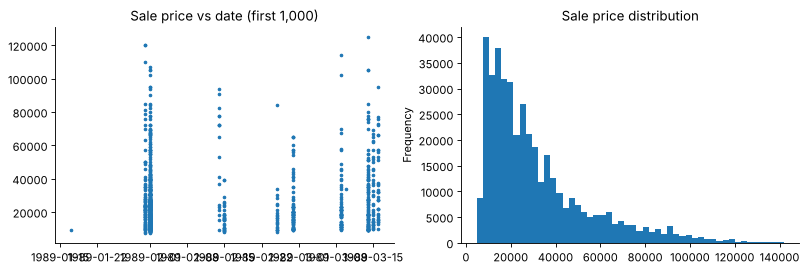

In [3]:
BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
print(df.shape)
print(df["saledate"].dtype, "|", df["saledate"].min().date(), "->", df["saledate"].max().date())
df = df.sort_values(by="saledate").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].scatter(df["saledate"][:1000], df["SalePrice"][:1000], s=5); axes[0].set_title("Sale price vs date (first 1,000)")
df["SalePrice"].plot.hist(bins=50, ax=axes[1], title="Sale price distribution")
plt.show()

<a id="feature-engineering-from-dates"></a>

### Feature Engineering from Dates

A raw timestamp means little to a tree model, but its parts carry signal: year, month, day, day of week and day of year
(auctions may follow seasons and weekly patterns). Add them as columns and drop the original.

In [4]:
BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df = df.sort_values("saledate").reset_index(drop=True)

def add_datetime_features(frame):
    """Expand 'saledate' into numeric date parts and drop the original column."""
    frame = frame.copy()
    frame["saleYear"] = frame["saledate"].dt.year
    frame["saleMonth"] = frame["saledate"].dt.month
    frame["saleDay"] = frame["saledate"].dt.day
    frame["saleDayofweek"] = frame["saledate"].dt.dayofweek
    frame["saleDayofyear"] = frame["saledate"].dt.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(df)
print(df[["saleYear", "saleMonth", "saleDay", "saleDayofweek", "saleDayofyear"]].head(3))
print("Missing values in the 10 worst columns:\n", df.isna().sum().sort_values(ascending=False).head(10))

   saleYear  saleMonth  saleDay  saleDayofweek  saleDayofyear
0      1989          1       17              1             17
1      1989          1       31              1             31
2      1989          1       31              1             31


Missing values in the 10 worst columns:
 Blade_Width          386715
Enclosure_Type       386715
Engine_Horsepower    386715
Tip_Control          386715
Pushblock            386715
Blade_Extension      386715
Scarifier            386704
Grouser_Tracks       367823
Hydraulics_Flow      367823
Coupler_System       367724
dtype: int64


<a id="turning-everything-into-numbers"></a>

### Turning Everything into Numbers

The quick pandas approach turns every text column into the `category` dtype and then into integer codes (adding 1 so
missing becomes 0 instead of −1). It fills numeric gaps with the **median**, which is robust to outliers, and adds a binary
`<column>_is_missing` flag for each, because the fact that a value is missing can itself be informative.

In [5]:
# The quick pandas-only approach, on a sample of rows.
BULLDOZER = DATA / "bluebook-for-bulldozers"
df_tmp = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"], nrows=50_000)

for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if content.isna().any():
            df_tmp[label + "_is_missing"] = content.isna()
            df_tmp[label] = content.fillna(content.median())
    elif not pd.api.types.is_datetime64_any_dtype(content):
        df_tmp[label + "_is_missing"] = content.isna()
        df_tmp[label] = pd.Categorical(content).codes + 1          # missing (-1) becomes 0

print("Remaining missing values:", int(df_tmp.isna().sum().sum()))
print(df_tmp[["UsageBand", "UsageBand_is_missing", "MachineHoursCurrentMeter",
              "MachineHoursCurrentMeter_is_missing"]].head(3))

Remaining missing values: 0
   UsageBand  UsageBand_is_missing  MachineHoursCurrentMeter  \
0          2                 False                      68.0   
1          2                 False                    4640.0   
2          1                 False                    2838.0   

   MachineHoursCurrentMeter_is_missing  
0                                False  
1                                False  
2                                False  


**Watch out:** doing this on the full dataset *before* splitting lets the validation rows influence the medians and the
category codes, which is mild leakage. The test set would also need exactly the same mapping later. The rest of this
section does the same work (median fills, missing-value flags, categories as integers) inside a `ColumnTransformer` fitted
on the training data only.

<a id="splitting-by-time-and-measuring-honestly"></a>

### Splitting by Time and Measuring Honestly

Fit a model on everything and score it on the same data, and you'll see a suspiciously good R². Evaluation matters as much
as fitting.

The split has to mirror reality. **Train on sales before 2012 and validate on 2012**, the same way the competition splits.
Never shuffle time-ordered data. A `show_scores()` helper reports MAE, RMSLE and R² on both sets, so overfitting shows up
as a gap between them.

`max_samples=10_000` makes each tree train on a random 10,000 rows. That gives slightly lower accuracy but experiments run
in seconds rather than minutes, which is what you want while you're still exploring.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    """Expand 'saledate' into numeric date parts and drop the original column."""
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df = add_datetime_features(df.sort_values("saledate"))
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train = train.drop(columns="SalePrice"), train["SalePrice"]
X_valid, y_valid = valid.drop(columns="SalePrice"), valid["SalePrice"]
print("train:", X_train.shape, "valid:", X_valid.shape)

categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = X_train.select_dtypes(include="number").columns.tolist()
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),    # median + *_is_missing flags
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                           encoded_missing_value=-1), categorical),            # categories -> integers
])

def show_scores(model):
    """MAE, RMSLE and R^2 on the training and validation sets."""
    train_preds, valid_preds = model.predict(X_train), model.predict(X_valid)
    return {"Training MAE": mean_absolute_error(y_train, train_preds),
            "Valid MAE": mean_absolute_error(y_valid, valid_preds),
            "Training RMSLE": root_mean_squared_log_error(y_train, train_preds),
            "Valid RMSLE": root_mean_squared_log_error(y_valid, valid_preds),
            "Training R^2": r2_score(y_train, train_preds), "Valid R^2": r2_score(y_valid, valid_preds)}

# max_samples=10_000: each tree sees 10,000 rows, so experiments take seconds instead of minutes.
quick_model = Pipeline([("prep", preprocessor),
                        ("model", RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000))])
quick_model.fit(X_train, y_train)
print({k: round(v, 3) for k, v in show_scores(quick_model).items()})

train: (401125, 56) valid: (11573, 56)


{'Training MAE': 5561.9, 'Valid MAE': 7167.082, 'Training RMSLE': 0.258, 'Valid RMSLE': 0.293, 'Training R^2': 0.861, 'Valid R^2': 0.832}


<a id="tuning-and-faster-alternatives"></a>

### Tuning and Faster Alternatives

`RandomizedSearchCV` over `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` and `max_features` (still on
the 10,000-row samples) finds good settings cheaply. A forest with 40 trees, `min_samples_split=14` and `max_features=0.5`,
trained on all the rows, is a strong configuration for this data.

`HistGradientBoostingRegressor` is a much faster alternative at this scale and handles missing values natively. RMSLE needs
non-negative predictions, so clip them at zero.

In [7]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_log_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False,
                                       parse_dates=["saledate"]).sort_values("saledate"))
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train = train.drop(columns="SalePrice"), train["SalePrice"]
X_valid, y_valid = valid.drop(columns="SalePrice"), valid["SalePrice"]
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = X_train.select_dtypes(include="number").columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
         categorical)])

rf_grid = {"model__n_estimators": np.arange(10, 100, 10), "model__max_depth": [None, 3, 5, 10],
           "model__min_samples_split": np.arange(2, 20, 2), "model__min_samples_leaf": np.arange(1, 20, 2),
           "model__max_features": [0.5, 1.0, "sqrt"]}
search = RandomizedSearchCV(
    Pipeline([("prep", make_preprocessor()),
              ("model", RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000))]),
    rf_grid, n_iter=5, cv=3, random_state=42).fit(X_train, y_train)
print("Best (randomized, 5 iterations):", search.best_params_)

start = time.time()
ideal_model = Pipeline([("prep", make_preprocessor()),
                        ("model", RandomForestRegressor(n_estimators=40, min_samples_leaf=1, min_samples_split=14,
                                                        max_features=0.5, n_jobs=-1, random_state=42))])
ideal_model.fit(X_train, y_train)
print(f"Ideal random forest: valid RMSLE {root_mean_squared_log_error(y_valid, ideal_model.predict(X_valid)):.4f} "
      f"({time.time() - start:.0f}s)")

start = time.time()
hgb = Pipeline([("prep", make_preprocessor()), ("model", HistGradientBoostingRegressor(max_iter=500, random_state=42))])
hgb.fit(X_train, y_train)
preds = np.clip(hgb.predict(X_valid), 0, None)               # RMSLE needs non-negative predictions
print(f"HistGradientBoosting: valid RMSLE {root_mean_squared_log_error(y_valid, preds):.4f} ({time.time() - start:.0f}s)")

Best (randomized, 5 iterations): {'model__n_estimators': np.int64(60), 'model__min_samples_split': np.int64(12), 'model__min_samples_leaf': np.int64(1), 'model__max_features': 1.0, 'model__max_depth': None}


Ideal random forest: valid RMSLE 0.2464 (52s)


HistGradientBoosting: valid RMSLE 0.2645 (38s)


<a id="predicting-on-the-test-set"></a>

### Predicting on the Test Set

The test data must go through *exactly* the same preprocessing as the training data. With hand-written pandas steps, that's
where bugs creep in, for example a `_is_missing` column that never appears because the test set has no gaps in that column.
A fitted pipeline avoids the whole problem. It applies the learned medians and category mappings, and unseen categories map
to −1 instead of crashing.

The final model trains on train + validation together, and predictions are written in the competition's format of two
columns, `SalesID` and `SalePrice`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"

def add_datetime_features(frame):
    frame = frame.copy()
    d = frame["saledate"].dt
    frame["saleYear"], frame["saleMonth"], frame["saleDay"] = d.year, d.month, d.day
    frame["saleDayofweek"], frame["saleDayofyear"] = d.dayofweek, d.dayofyear
    return frame.drop(columns="saledate")

df = add_datetime_features(pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False,
                                       parse_dates=["saledate"]))
X, y = df.drop(columns="SalePrice"), df["SalePrice"]
categorical = X.select_dtypes(exclude="number").columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()
final_model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1),
         categorical)])),
    ("model", RandomForestRegressor(n_estimators=40, min_samples_split=14, max_features=0.5,
                                    n_jobs=-1, random_state=42))]).fit(X, y)       # train + valid together

df_test = add_datetime_features(pd.read_csv(BULLDOZER / "Test.csv", low_memory=False, parse_dates=["saledate"]))
submission = pd.DataFrame({"SalesID": df_test["SalesID"], "SalePrice": final_model.predict(df_test)})
submission.to_csv("bulldozer-test-predictions.csv", index=False)
print(submission.shape); print(submission.head())

(12457, 2)
   SalesID     SalePrice
0  1227829  15051.187195
1  1227844  32045.696113
2  1227847  51317.514947
3  1227848  95011.549423
4  1227863  27797.279957


<a id="what-drives-the-price"></a>

### What Drives the Price

A random forest's `feature_importances_` show which columns drove the predictions. `YearMade` and `ProductSize` come out
on top, which makes sense: newer, bigger machines cost more. Results like this are worth checking with someone who knows
the domain, and they make the model far easier to explain to stakeholders.

YearMade              0.182
ProductSize           0.145
Enclosure             0.081
fiSecondaryDesc       0.075
saleYear              0.070
fiProductClassDesc    0.051
ModelID               0.046
fiModelDesc           0.042
SalesID               0.041
fiBaseModel           0.031
dtype: float64


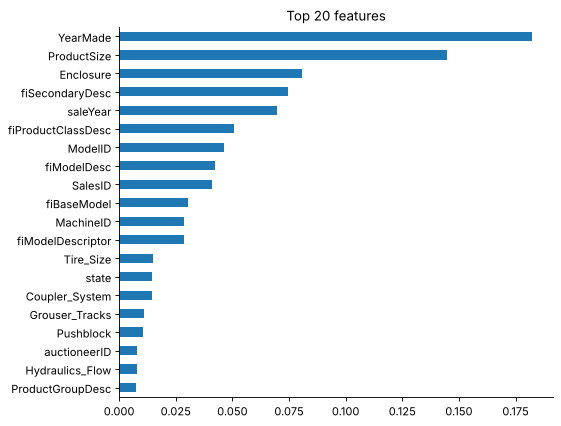

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
df["saleYear"] = df["saledate"].dt.year
df = df.drop(columns="saledate")
X, y = df.drop(columns="SalePrice"), df["SalePrice"]
categorical = X.select_dtypes(exclude="number").columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

model = Pipeline([
    ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), numeric),
                                ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                       encoded_missing_value=-1), categorical)],
                               verbose_feature_names_out=False)),
    ("model", RandomForestRegressor(n_estimators=40, max_features=0.5, max_samples=50_000,
                                    n_jobs=-1, random_state=42))]).fit(X, y)

importances = pd.Series(model["model"].feature_importances_, index=model["prep"].get_feature_names_out())
top = importances.sort_values(ascending=False).head(20)
print(top.round(3).head(10))
top.sort_values().plot.barh(figsize=(7, 6), title="Top 20 features"); plt.show()

#### Exercise 8

On the bulldozer data, compare validation RMSLE for three ways of handling the categorical columns, using the date features
and `RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000)` where a forest is used: `OrdinalEncoder`,
dropping the categorical columns entirely, and `HistGradientBoostingRegressor(categorical_features="from_dtype")` with
native categorical support (which allows at most 255 categories per column).

#### Solution 8

*Try it yourself before running this cell.*

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_log_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

BULLDOZER = DATA / "bluebook-for-bulldozers"
df = pd.read_csv(BULLDOZER / "TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
d = df["saledate"].dt
df["saleYear"], df["saleMonth"], df["saleDayofyear"] = d.year, d.month, d.dayofyear
df = df.drop(columns="saledate")
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]
X_train, y_train, X_valid, y_valid = (train.drop(columns="SalePrice"), train["SalePrice"],
                                      valid.drop(columns="SalePrice"), valid["SalePrice"])
cat = X_train.select_dtypes(exclude="number").columns.tolist()
num = X_train.select_dtypes(include="number").columns.tolist()
rf = lambda: RandomForestRegressor(n_jobs=-1, random_state=42, max_samples=10_000)

candidates = {
    "ordinal encoder": Pipeline([("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), cat)])),
        ("model", rf())]),
    "numeric only": Pipeline([("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), num)])),
                              ("model", rf())]),
}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    print(f"{name:16s} RMSLE {root_mean_squared_log_error(y_valid, model.predict(X_valid)):.4f}")

# Native categorical support allows at most 255 categories per column, so high-cardinality
# columns (e.g. fiModelDesc, ~5,000 values) become integer codes instead.
low_card = [c for c in cat if X_train[c].nunique() <= 255]
categories = {c: pd.Categorical(X_train[c]).categories for c in cat}       # learned from training data only
def prepare(frame):
    frame = frame.copy()
    for c in cat:
        values = pd.Categorical(frame[c], categories=categories[c])
        frame[c] = values if c in low_card else values.codes           # unseen/missing -> -1
    return frame
hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42).fit(prepare(X_train), y_train)
preds = np.clip(hgb.predict(prepare(X_valid)), 0, None)
print(f"{'native categorical':16s} RMSLE {root_mean_squared_log_error(y_valid, preds):.4f}")

ordinal encoder  RMSLE 0.2917


numeric only     RMSLE 0.4649


native categorical RMSLE 0.2753


<a id="cheatsheet-time-series-regression"></a>

### Cheatsheet: Time-Series Regression

```python
df = pd.read_csv(path, low_memory=False, parse_dates=["saledate"]).sort_values("saledate")
df["saleYear"] = df["saledate"].dt.year          # .month .day .dayofweek .dayofyear
train, valid = df[df["saleYear"] != 2012], df[df["saleYear"] == 2012]     # split by time, never randomly
ColumnTransformer([("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
                   ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                          encoded_missing_value=-1), cat_cols)])
RandomForestRegressor(n_jobs=-1, max_samples=10_000)     # fast experiments
root_mean_squared_log_error(y_valid, preds)               # replaces mean_squared_log_error(..., squared=False)
```

<a id="14-forecasting-time-series-with-prophet"></a>

## 14. Forecasting Time Series with Prophet

The next two projects forecast the future of a single series: monthly crime counts in Chicago and weekly avocado prices.
Prophet, an open-source library from Meta, is built for exactly this kind of business series: a few years of daily,
weekly or monthly observations with trends that bend and strong yearly patterns.

<a id="how-prophet-models-a-series"></a>

### How Prophet Models a Series

Prophet fits an **additive** model: the series is the sum of a few interpretable pieces.

$$y(t) = g(t) + s(t) + h(t) + \varepsilon_t$$

- $g(t)$, the **trend**: a piecewise-linear line whose slope may change at automatically detected **changepoints**.
- $s(t)$, **seasonality**: yearly and weekly cycles, modelled with Fourier terms (sums of sines and cosines).
- $h(t)$, **holidays and events**: optional one-off effects you supply.
- $\varepsilon_t$: noise the model doesn't explain.

```mermaid
flowchart LR
    A["DataFrame<br/>ds = date, y = value"] --> B["Prophet().fit(df)"]
    B --> C["make_future_dataframe<br/>(periods, freq)"]
    C --> D["predict()<br/>yhat, yhat_lower, yhat_upper"]
    D --> E["plot()<br/>plot_components()"]
```

Because the pieces are separate, `plot_components()` shows each one, which makes the forecast easy to explain. The
uncertainty band (`yhat_lower` to `yhat_upper`) comes from simulating future trend changes, so it widens the further
out you forecast.

Prophet's one firm requirement is the input format: a DataFrame with a date column called `ds` and a value column
called `y`.

**Watch out:** the package was renamed from `fbprophet` to `prophet` in version 1.0. `from fbprophet import Prophet`
fails on current installs; use `from prophet import Prophet`.

<a id="15-project-forecasting-chicago-crime"></a>

## 15. Project: Forecasting Chicago Crime

The City of Chicago publishes every reported crime since 2001. We'll explore which crimes happen most and where, look
at the long-term trend, and forecast the monthly count two years ahead.

<a id="from-19-gb-of-reports-to-daily-counts"></a>

### From 1.9 GB of Reports to Daily Counts

The raw export comes as four CSV files with 7.9 million rows and 23 columns. A forecast of total counts only needs
three of them: the date, the crime type and the location description. Reading the files in chunks with `usecols`
keeps memory low, and grouping by day and type shrinks everything to 130,000 rows.

**Watch out:** the four files overlap. About 1.8 million rows are exact repeats of the same incident `ID`, and keeping
them doubles the counts for 2006–2010. De-duplicate on `ID` before counting.

This is the script I ran on the raw files (it takes a few minutes and about 2 GB of RAM):

```python
import glob
import pandas as pd

cols = ["ID", "Date", "Primary Type", "Location Description"]
df = pd.concat(
    chunk
    for f in sorted(glob.glob("Chicago_Crimes_*.csv"))
    for chunk in pd.read_csv(f, usecols=cols, on_bad_lines="skip", chunksize=1_000_000, low_memory=False)
).drop_duplicates("ID")
df["date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce").dt.date

(df.groupby(["date", "Primary Type"]).size().rename("count").reset_index()
   .rename(columns={"Primary Type": "primary_type"})
   .to_csv("data/chicago/chicago-crimes-daily-by-type.csv", index=False))
(df["Location Description"].value_counts().rename_axis("location_description").rename("count")
   .reset_index().to_csv("data/chicago/chicago-crimes-location-counts.csv", index=False))
```

**Watch out:** `error_bad_lines=False` was removed from `read_csv` in pandas 2.0. Use `on_bad_lines="skip"`.

In [11]:
daily = pd.read_csv(DATA / "chicago" / "chicago-crimes-daily-by-type.csv", parse_dates=["date"])
locations = pd.read_csv(DATA / "chicago" / "chicago-crimes-location-counts.csv")
print(daily.head(3).to_string())
print(f"\n{daily['count'].sum():,} incidents, {daily['primary_type'].nunique()} crime types, "
      f"{daily['date'].min().date()} to {daily['date'].max().date()}")

        date primary_type  count
0 2001-01-01      ASSAULT     70
1 2001-01-01      BATTERY    296
2 2001-01-01     BURGLARY     66

6,170,812 incidents, 35 crime types, 2001-01-01 to 2017-01-18


<a id="what-and-where"></a>

### What and Where

Before forecasting, a quick look at which crimes dominate and where they happen.

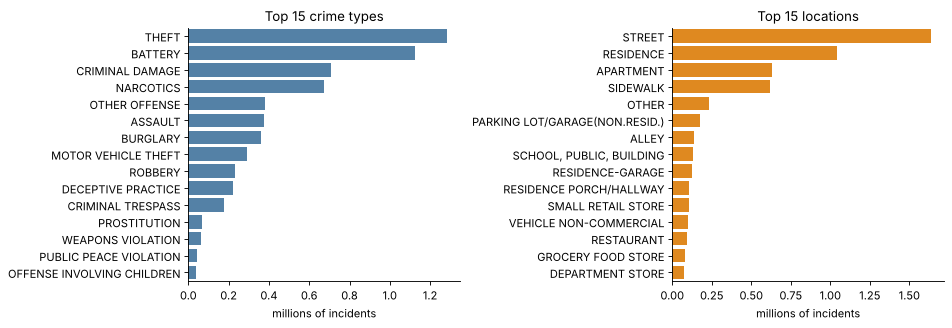

primary_type
THEFT              20.8
BATTERY            18.2
CRIMINAL DAMAGE    11.5
NARCOTICS          10.9
OTHER OFFENSE       6.2


In [12]:
by_type = daily.groupby("primary_type")["count"].sum().nlargest(15)
top_loc = locations.head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=by_type.values / 1e6, y=by_type.index, ax=ax1, color="steelblue")
ax1.set_title("Top 15 crime types"); ax1.set_xlabel("millions of incidents"); ax1.set_ylabel("")
sns.barplot(x=top_loc["count"] / 1e6, y=top_loc["location_description"], ax=ax2, color="darkorange")
ax2.set_title("Top 15 locations"); ax2.set_xlabel("millions of incidents"); ax2.set_ylabel("")
plt.tight_layout(); plt.show()
print((by_type / daily["count"].sum() * 100).round(1).head(5).to_string())

Theft and battery together account for about 40% of all reports, and most incidents happen on the street or in homes.

<a id="resampling-yearly-quarterly-and-monthly-counts"></a>

### Resampling: Yearly, Quarterly and Monthly Counts

With a `DatetimeIndex`, `resample()` regroups a series to any frequency, like `groupby` for time. Summing daily totals
by year shows the trend; by month it shows the seasonal cycle on top.

**Watch out:** the frequency aliases changed in pandas 2.2. `"Y"`, `"Q"` and `"M"` (meaning period end) are now `"YE"`,
`"QE"` and `"ME"`; month **start** is `"MS"`. The old letters raise errors in pandas 3.

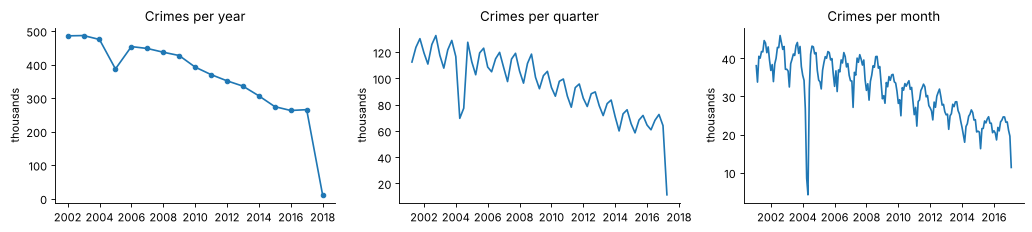

date
2015-12-31    262995
2016-12-31    265462
2017-12-31     11357
Freq: YE-DEC


In [13]:
total = daily.groupby("date")["count"].sum()           # one value per day, DatetimeIndex

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (rule, label) in zip(axes, [("YE", "year"), ("QE", "quarter"), ("ME", "month")]):
    series = total.resample(rule).sum()
    ax.plot(series.index, series.values / 1e3, marker="o" if rule == "YE" else None, ms=4)
    ax.set_title(f"Crimes per {label}"); ax.set_ylabel("thousands")
plt.tight_layout(); plt.show()
print(total.resample("YE").sum().tail(3).to_string())

Reported crime fell steadily, from about 486,000 in 2001 to about 265,000 in 2016 (the dip in 2004 is a data gap,
covered below). The 2017 total is tiny because the
export stops on 18 January 2017. That last, partial period would look like a crash in a monthly series, so we drop it
before modelling.

<a id="building-the-monthly-series"></a>

### Building the Monthly Series

Prophet works on any regular frequency. Monthly totals smooth out day-to-day noise and still show the seasonal cycle.

**Watch out:** this export has a hole. From mid-February to early May 2004 there are only a few hundred reports a week
instead of the usual 8,000 to 9,000, which is why 2004 looks like a dip in the yearly chart. Those months aren't
low-crime months; they're missing data. Fed to the model as real values, they would drag the trend and seasonality
down. Prophet accepts `NaN` in `y` and simply skips those rows, so we mark the four affected months as unknown.

In [14]:
monthly = total.resample("MS").sum()                   # month-start labels suit Prophet's monthly forecasts
monthly = monthly[monthly.index < "2017-01-01"]        # drop the partial final month

print("monthly totals Jan–Jun 2004 (thousands):", (monthly["2004-01":"2004-06"] / 1e3).round(1).tolist())
monthly.loc["2004-02-01":"2004-05-01"] = np.nan        # months hit by the gap: unknown, not zero
chicago_df = monthly.reset_index()
chicago_df.columns = ["ds", "y"]                       # Prophet's required column names
print(chicago_df.shape)
print(chicago_df.tail(3).to_string(index=False))

monthly totals Jan–Jun 2004 (thousands): [34.2, 26.8, 8.5, 4.2, 32.0, 41.1]
(192, 2)
        ds       y
2016-10-01 23314.0
2016-11-01 21140.0
2016-12-01 19580.0


<a id="checking-accuracy-on-a-holdout-period"></a>

### Checking Accuracy on a Holdout Period

A forecast is only useful if we know how wrong it tends to be. As with the
[bulldozer prices](#splitting-by-time-and-measuring-honestly), the test data must come after the training data. Hold
back the last two years, fit on everything before,
and compare. **MAPE**, the mean absolute percentage error, is easy to communicate: "on average the forecast was off by
X%".

holdout MAPE 2015–2016: 8.6%


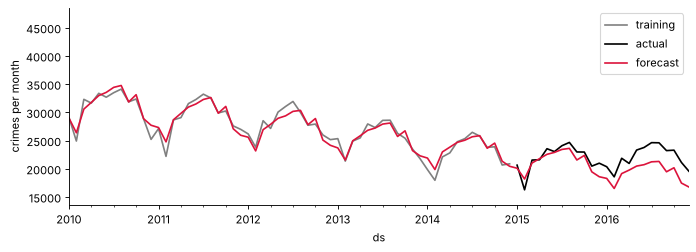

In [15]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_percentage_error

train = chicago_df[chicago_df["ds"] < "2015-01-01"]
test = chicago_df[chicago_df["ds"] >= "2015-01-01"]

m = Prophet(seasonality_mode="multiplicative", yearly_seasonality=5)         # seasonal swings shrink as crime falls
m.fit(train)
future = m.make_future_dataframe(periods=len(test), freq="MS")
fc = m.predict(future)
pred = fc.set_index("ds").loc[test["ds"], "yhat"]
print(f"holdout MAPE 2015–2016: {mean_absolute_percentage_error(test['y'], pred):.1%}")

ax = train.set_index("ds")["y"].plot(figsize=(10, 3.2), label="training", color="grey")
test.set_index("ds")["y"].plot(ax=ax, label="actual", color="black")
fc.set_index("ds")["yhat"].plot(ax=ax, label="forecast", color="crimson")
ax.fill_between(fc["ds"], fc["yhat_lower"], fc["yhat_upper"], color="crimson", alpha=0.15)
ax.set_xlim(pd.Timestamp("2010-01-01"), None); ax.set_ylabel("crimes per month"); ax.legend(); plt.show()

I used `seasonality_mode="multiplicative"` because the size of the summer peak scales with the overall level: when total
crime halves, so does the summer bump. With the default additive mode, Prophet adds the same absolute seasonal swing
every year. Try both in the exercise below; the holdout MAPE tells you which fits better.

`yearly_seasonality=5` sets the number of Fourier terms for the yearly cycle. The default (10) is tuned for daily data;
with only 12 points per year it can draw wild swings between the months that no data point ever checks. A lower order
keeps the seasonal curve smooth.

<a id="forecasting-two-years-ahead"></a>

### Forecasting Two Years Ahead

For the real forecast, refit on all the data and extend 24 months.

**Watch out:** `make_future_dataframe(periods=365)` defaults to **daily** steps. On monthly data that silently produces
365 daily predictions instead of a year of months. Pass `freq="MS"` (or `"W"` for weekly data) so periods are counted in
the series' own unit.

        ds    yhat  yhat_lower  yhat_upper
2018-10-01 19908.0     18590.0     21342.0
2018-11-01 17340.0     15929.0     18684.0
2018-12-01 16681.0     15265.0     17910.0


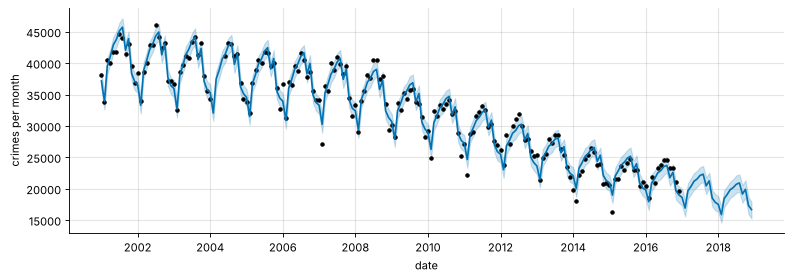

In [16]:
m = Prophet(seasonality_mode="multiplicative", yearly_seasonality=5).fit(chicago_df)
future = m.make_future_dataframe(periods=24, freq="MS")
forecast = m.predict(future)
print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(3).round({"yhat": 0, "yhat_lower": 0, "yhat_upper": 0})
      .to_string(index=False))

fig = m.plot(forecast, xlabel="date", ylabel="crimes per month", figsize=(10, 3.6))
plt.show()

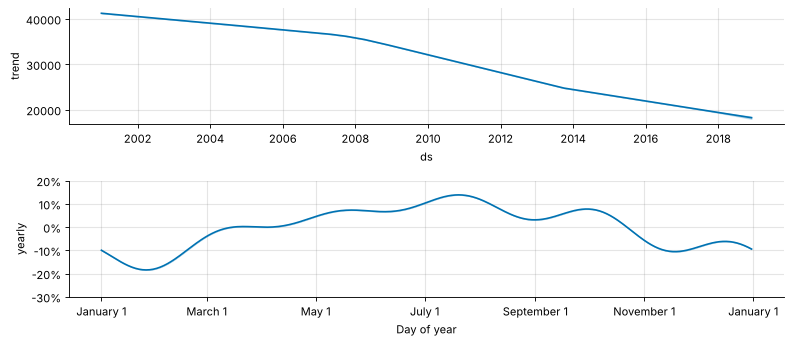

In [17]:
fig = m.plot_components(forecast, figsize=(10, 4.4))
plt.show()

The components separate the story cleanly: a long, steady decline in the trend, and a yearly cycle that peaks in July
and August and bottoms out in February. Warm weather means more people outside, and more crime.

**Cheatsheet: Prophet forecasting**

| Step | Code |
|---|---|
| Import | `from prophet import Prophet` (not `fbprophet`) |
| Required format | `df.rename(columns={"date": "ds", "value": "y"})` |
| Aggregate first | `series.resample("MS").sum()` (`"ME"`, `"QE"`, `"YE"` for period ends) |
| Fit | `m = Prophet(seasonality_mode="multiplicative", yearly_seasonality=5).fit(df)` (lower Fourier order for monthly data) |
| Future dates | `m.make_future_dataframe(periods=24, freq="MS")` |
| Predict | `fc = m.predict(future)` → `yhat`, `yhat_lower`, `yhat_upper` |
| Plots | `m.plot(fc)`, `m.plot_components(fc)` |
| Evaluate | Hold out the last periods, then `mean_absolute_percentage_error` |

#### Exercise 9

Forecast **THEFT** on its own. Build its monthly series (dropping the partial month), hold out 2015–2016, and compare
the holdout MAPE of `seasonality_mode="additive"` against `"multiplicative"`.

#### Solution 9

*Try it yourself before running this cell.*

In [18]:
theft = daily[daily["primary_type"] == "THEFT"].set_index("date")["count"].resample("MS").sum().loc[:"2016-12-01"]
theft.loc["2004-02-01":"2004-05-01"] = np.nan          # same data gap as the total
theft = theft.reset_index()
theft.columns = ["ds", "y"]
tr, te = theft[theft["ds"] < "2015-01-01"], theft[theft["ds"] >= "2015-01-01"]
for mode in ("additive", "multiplicative"):
    mm = Prophet(seasonality_mode=mode, yearly_seasonality=5).fit(tr)
    p = mm.predict(mm.make_future_dataframe(periods=len(te), freq="MS")).set_index("ds").loc[te["ds"], "yhat"]
    print(f"{mode:15} MAPE {mean_absolute_percentage_error(te['y'], p):.1%}")

additive        MAPE 7.9%
multiplicative  MAPE 7.4%


<a id="16-project-forecasting-avocado-prices"></a>

## 16. Project: Forecasting Avocado Prices

The Hass Avocado Board publishes weekly retail scan data. This version covers 2015 to March 2018: average price and
volumes for conventional and organic avocados in 54 regions. The goal is a price forecast for the next year.

<a id="exploring-the-price-data"></a>

### Exploring the Price Data

**Watch out:** the CSV starts with an unnamed index column. Read it with `index_col=0` or you get a meaningless
`Unnamed: 0` column.

In [19]:
avocado_df = pd.read_csv(DATA / "avocado.csv", index_col=0, parse_dates=["Date"]).sort_values("Date")
print(avocado_df.shape)
print(avocado_df[["Date", "AveragePrice", "Total Volume", "type", "year", "region"]].head(3).to_string(index=False))
print("\nregions:", avocado_df["region"].nunique(), "| types:", avocado_df["type"].unique().tolist())
print("rows per year:", avocado_df["year"].value_counts().sort_index().to_dict())

(18249, 13)
      Date  AveragePrice  Total Volume    type  year             region
2015-01-04          1.75      27365.89 organic  2015          Southeast
2015-01-04          1.49      17723.17 organic  2015            Chicago
2015-01-04          1.68       2896.72 organic  2015 HarrisburgScranton

regions: 54 | types: ['organic', 'conventional']
rows per year: {2015: 5615, 2016: 5616, 2017: 5722, 2018: 1296}


<a id="one-series-at-a-time"></a>

### One Series at a Time

Here's the trap in this dataset. Every week has 108 rows (54 regions × 2 types). Plotting `AveragePrice` against
`Date` for the whole table, or handing the whole table to Prophet, mixes all of them into one jagged cloud: cheap
conventional avocados in Houston next to expensive organic ones in San Francisco. Some "regions" are even aggregates of
others (`TotalUS`, `West`, `California`).

A forecast needs **one** series. Pick a region and a type, or aggregate explicitly.

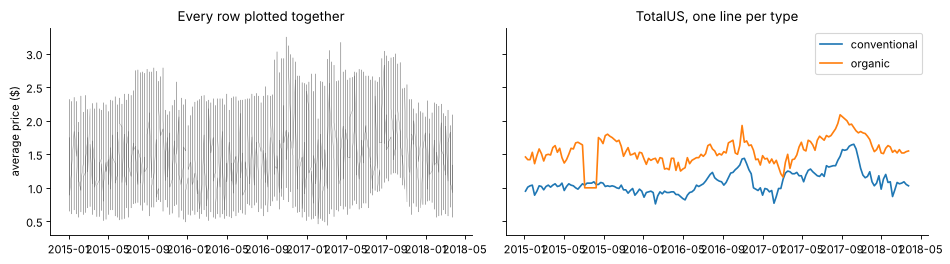

In [20]:
total_us = avocado_df[avocado_df["region"] == "TotalUS"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
ax1.plot(avocado_df["Date"], avocado_df["AveragePrice"], lw=0.3, color="grey")
ax1.set_title("Every row plotted together"); ax1.set_ylabel("average price ($)")
for kind, g in total_us.groupby("type"):
    ax2.plot(g["Date"], g["AveragePrice"], label=kind)
ax2.set_title("TotalUS, one line per type"); ax2.legend()
plt.tight_layout(); plt.show()

Organic avocados cost roughly 40% more, both types share the same seasonal rhythm, and 2017 had a sharp price spike
that peaked in the autumn. We'll forecast the US conventional price.

Look closely at the organic line in July–September 2015: the price sits at exactly $1.00 for weeks, with whole-number
volumes. Those are placeholder values in the source data, not real prices. The conventional series doesn't have the
problem; if you model organic prices, drop or interpolate those weeks first.

<a id="forecasting-the-us-price"></a>

### Forecasting the US Price

First a holdout check on the last 26 weeks, against the simplest possible baseline, then the real 52-week forecast.

In [21]:
us_conv = (total_us[total_us["type"] == "conventional"][["Date", "AveragePrice"]]
           .rename(columns={"Date": "ds", "AveragePrice": "y"}))
print(us_conv.shape, us_conv["ds"].dt.day_name().unique())

cut = us_conv["ds"].max() - pd.Timedelta(weeks=26)
train, test = us_conv[us_conv["ds"] <= cut], us_conv[us_conv["ds"] > cut]
m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(train)
fc = m.predict(m.make_future_dataframe(periods=len(test), freq="W-SUN"))
p = fc.set_index("ds").loc[test["ds"], "yhat"]
naive = np.full(len(test), train["y"].iloc[-1])           # "price stays where it was"
print(f"26-week holdout MAPE: Prophet {mean_absolute_percentage_error(test['y'], p):.1%}, "
      f"last-value baseline {mean_absolute_percentage_error(test['y'], naive):.1%}")

(169, 2) <StringArray>
['Sunday']
Length: 1, dtype: str
26-week holdout MAPE: Prophet 24.1%, last-value baseline 42.1%


The dates are all Sundays, so the future frame uses `freq="W-SUN"`. Weekly and daily seasonality are switched off
because one point per week can't reveal a within-week pattern.

The naive "last value" baseline is worth printing next to any forecast. Here both errors are large, because the
holdout starts in autumn 2017, right after the price spike peaked, and prices then fell fast. Prophet does better than
the baseline because its yearly seasonality expects winter prices to drop, but an error above 20% says this forecast
is a rough guide to direction and season, not a price list.

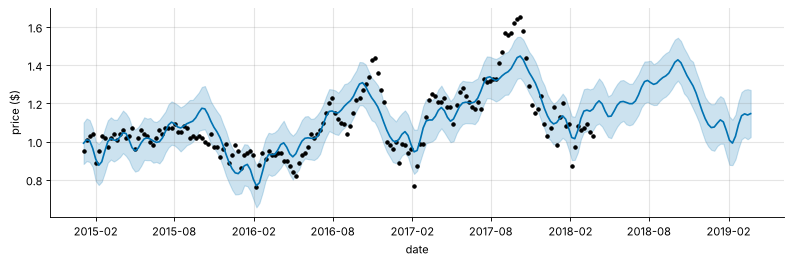

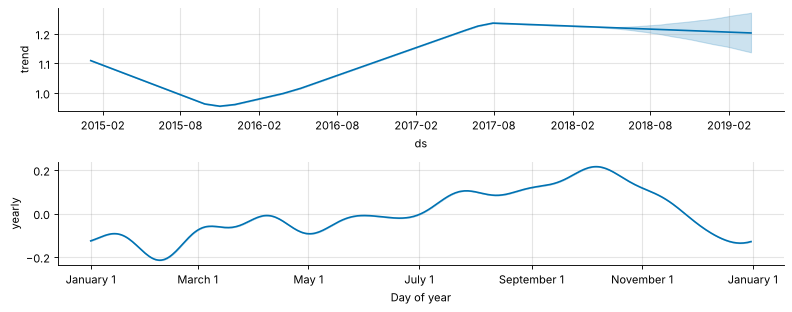

In [22]:
m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(us_conv)
forecast = m.predict(m.make_future_dataframe(periods=52, freq="W-SUN"))
fig = m.plot(forecast, xlabel="date", ylabel="price ($)", figsize=(10, 3.4)); plt.show()
fig = m.plot_components(forecast, figsize=(10, 4)); plt.show()

<a id="region-specific-forecasts"></a>

### Region-Specific Forecasts

A distributor in one market cares about its own prices. Filtering to a single region and type gives a cleaner series
than the national one. Here's the `West` region (itself an aggregate of the western markets), conventional avocados.

        ds  yhat  yhat_lower  yhat_upper
2019-03-17  1.21        1.09        1.34
2019-03-24  1.22        1.09        1.35


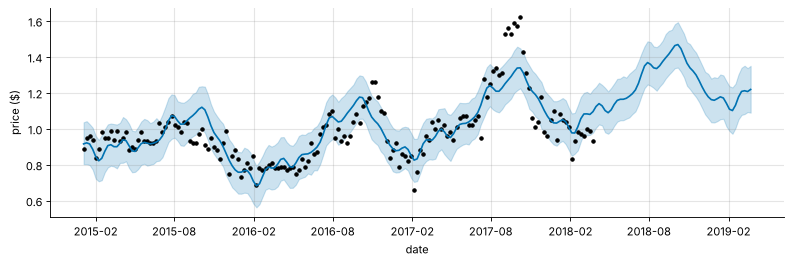

In [23]:
west = (avocado_df[(avocado_df["region"] == "West") & (avocado_df["type"] == "conventional")]
        [["Date", "AveragePrice"]].rename(columns={"Date": "ds", "AveragePrice": "y"}))
m_west = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(west)
fc_west = m_west.predict(m_west.make_future_dataframe(periods=52, freq="W-SUN"))
print(fc_west[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(2).round({"yhat": 2, "yhat_lower": 2, "yhat_upper": 2})
      .to_string(index=False))
fig = m_west.plot(fc_west, xlabel="date", ylabel="price ($)", figsize=(10, 3.4)); plt.show()

Note how wide the uncertainty band gets after a year. With only three years of history, which include one unusual
spike, Prophet is honest about how little it knows. A single year's forecast from three years of data should be read
as "the seasonal shape plus a rough level", not a precise price.

#### Exercise 10

Compare organic and conventional avocados in `TotalUS`. Fit one Prophet model per type and plot both 52-week forecasts
(`yhat`) on one chart, along with the history.

#### Solution 10

*Try it yourself before running this cell.*

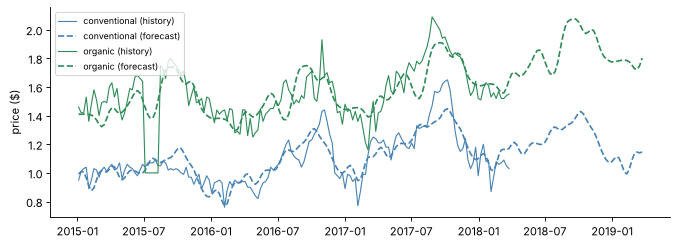

In [24]:
plt.figure(figsize=(10, 3.4))
for kind, color in (("conventional", "steelblue"), ("organic", "seagreen")):
    s = (total_us[total_us["type"] == kind][["Date", "AveragePrice"]]
         .rename(columns={"Date": "ds", "AveragePrice": "y"}))
    mk = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False).fit(s)
    f = mk.predict(mk.make_future_dataframe(periods=52, freq="W-SUN"))
    plt.plot(s["ds"], s["y"], color=color, lw=1, label=f"{kind} (history)")
    plt.plot(f["ds"], f["yhat"], color=color, ls="--", label=f"{kind} (forecast)")
plt.ylabel("price ($)"); plt.legend(fontsize=8); plt.show()